In [18]:
import pandas as pd
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Part 1: Understanding Product Categories
#### Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. Frequency Tables:
- Generate a frequency table for the product category.
- Which are the top 5 most listed product categories?

2. Visualizations:

- Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
- For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [20]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [22]:
df.shape

(2443651, 9)

In [24]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [28]:
frequency_table = df['category'].value_counts()
frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [38]:
ft_visualization = frequency_table.head(5)

/var/folders/y6/yy6xx0td03j17rtqbfny6l900000gn/T/ipykernel_17861/2275695205.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ft_visualization.index, y=ft_visualization.values, palette="Set3")


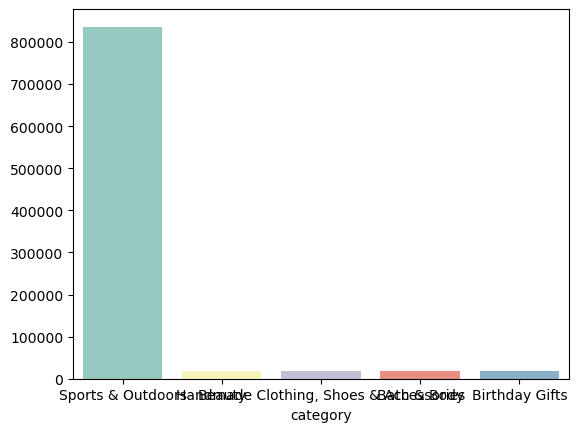

In [40]:
sns.barplot(x=ft_visualization.index, y=ft_visualization.values, palette="Set3")
plt.show();

In [56]:
top_4_cat = frequency_table.head(4)

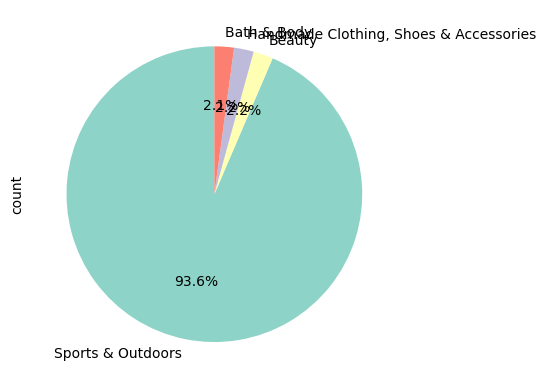

In [60]:
top_4_cat.plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))
plt.show();

# Part 2: Delving into Product Pricing
### Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. Measures of Centrality:

- Calculate the mean, median, and mode for the price of products.
- What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. Measures of Dispersion:

- Determine the variance, standard deviation, range, and interquartile range for product price.
- How varied are the product prices? Are there any indicators of a significant spread in prices?

3. Visualizations:

- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
- Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [63]:
df['price'].mean()

89.24380943923663

In [65]:
df['price'].median()

19.09

In [67]:
df['price'].mode()

0    9.99
Name: price, dtype: float64

#### The average (mean) price of products is 89.24, while the most common price (mode) is just 9.99. This large gap suggests that while many products are priced low, a smaller number of high-priced items are pulling the average up. The distribution is likely right-skewed, with a concentration of low-priced listings and a long tail of expensive ones.

In [72]:
variance = df['price'].var()
variance

119445.4853225653

In [74]:
std_dev = df['price'].std()
std_dev

345.6088617535223

In [80]:
range = df['price'].max() - df['price'].min()
range

100000.0

In [82]:
iqr = df['price'].quantile(0.75) - df['price'].quantile(0.25)
iqr

36.0

#### The product prices show a high degree of variability. The standard deviation of 345.61 and an extreme range of 100000 indicate the presence of very high-priced outliers. In contrast, the relatively small IQR of 36.00 suggests that most products are priced within a much narrower band, reinforcing the idea of a right-skewed distribution with a long tail of expensive items

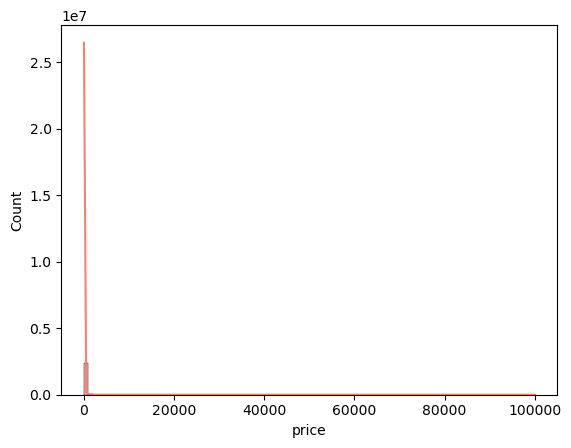

In [93]:
sns.histplot(df['price'], bins=100, kde=True, color="salmon")
plt.show()

In [107]:
# If most prices are low and only a few are very high, the bars at the left will be squished. 
# Zooming in on products who are cheaper than 500 can help with the visualization.

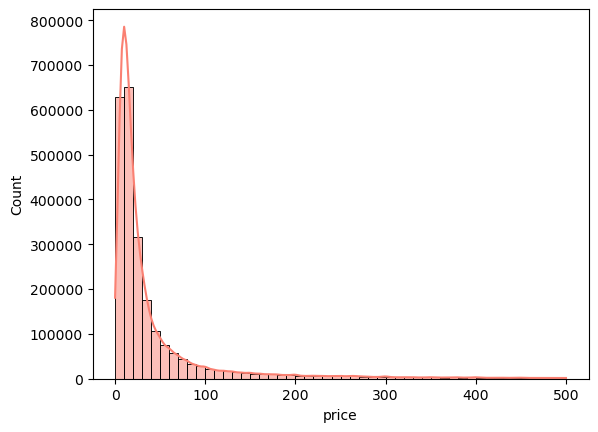

In [105]:
sns.histplot(df[df['price'] < 500]['price'], bins=50, kde=True, color="salmon")
plt.show()

<Axes: xlabel='price'>

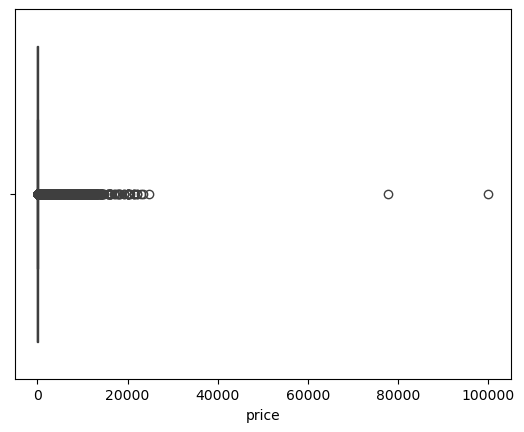

In [113]:
sns.boxplot(x=df['price'])

# Part 3: Unpacking Product Ratings
### Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. Measures of Centrality:

- Calculate the mean, median, and mode for the rating of products.
- How do customers generally rate products? Is there a common trend?

2. Measures of Dispersion:

- Determine the variance, standard deviation, and interquartile range for product rating.
- Are the ratings consistent, or is there a wide variation in customer feedback?

3. Shape of the Distribution:

- Calculate the skewness and kurtosis for the rating column.
- Are the ratings normally distributed, or do they lean towards higher or lower values?

4. Visualizations:

- Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [119]:
df['stars'].mean()

2.152836472966065

In [121]:
df['stars'].median()

0.0

In [123]:
df['stars'].mode()

0    0.0
Name: stars, dtype: float64

In [127]:
df['stars'].value_counts()

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
4.8      41858
3.9      36555
3.8      27876
3.7      21137
3.6      16219
3.5      14673
3.0      12819
4.9      11081
3.4      10355
1.0       8484
3.3       8269
3.2       5771
3.1       4679
2.0       3901
2.9       3341
2.8       2306
2.7       2104
2.5       2103
2.6       1579
2.4       1060
2.3        734
2.2        602
2.1        540
1.5        404
1.9        300
1.8        249
1.7        177
1.4        149
1.6        147
1.3         78
1.2         23
1.1          3
Name: count, dtype: int64

#### Mode is 0.0 and median is 0.0. indicating than more than 50% of the products were not rated by customers. Something that can be done to only take into consideration the rated product is the following:

In [142]:
rated_df = df[df['stars'] > 0]

In [144]:
rated_df['stars'].mean()

4.31916076222691

In [148]:
rated_df['stars'].median()

4.4

In [150]:
rated_df['stars'].mode()

0    4.5
Name: stars, dtype: float64

In [156]:
var_stars = df['stars'].var()
std_stars = df['stars'].std()
range_stars = df['stars'].max() - df['stars'].min()
iqr_stars = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

print(f"Ratings Variance: {var_stars}")
print(f"Ratings Standard Deviation: {std_stars}")
print(f"Range Ratings: {range_stars}")
print(f"IQR (Interquartile Range) Ratings: {iqr_stars}")

Ratings Variance: 4.81743402976196
Ratings Standard Deviation: 2.1948653785054697
Range Ratings: 5.0
IQR (Interquartile Range) Ratings: 4.4


In [158]:
var_stars_rat = rated_df['stars'].var()
std_stars_rat = rated_df['stars'].std()
range_stars_rat = rated_df['stars'].max() - rated_df['stars'].min()
iqr_stars_rat = rated_df['stars'].quantile(0.75) - rated_df['stars'].quantile(0.25)

print("Among rated products:")
print(f"Ratings Variance: {var_stars_rat}")
print(f"Ratings Standard Deviation: {std_stars_rat}")
print(f"Range Ratings: {range_stars_rat}")
print(f"IQR (Interquartile Range) Ratings: {iqr_stars_rat}")

Among rated products:
Ratings Variance: 0.30834337523805183
Ratings Standard Deviation: 0.5552867504614637
Range Ratings: 4.0
IQR (Interquartile Range) Ratings: 0.5


#### Among rated products, the ratings are highly consistent. The standard deviation is low (0.56) and the IQR is just 0.5, meaning most ratings cluster tightly around the center. Even though the range spans 4.0, the narrow spread of most values suggests that customers tend to give similar, consistently high ratings once they rate a product.

In [161]:
skewness_stars = df['stars'].skew()
kurtosis_stars = df['stars'].kurtosis()

skewness_stars, kurtosis_stars

(0.08120735761080985, -1.9260061280432985)

#### No significant skew, ratings are evenly balanced. Low kurtosis, ratings are consistently spread near the mean, with fewer outliers.

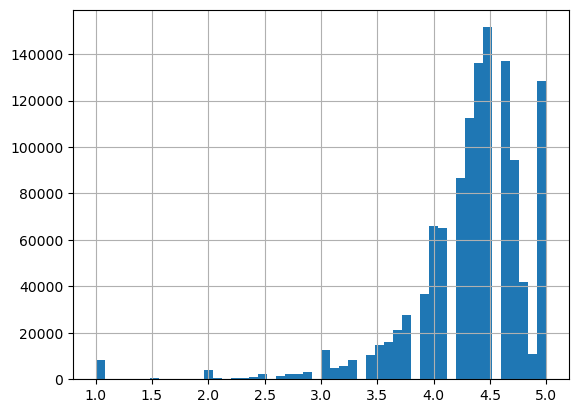

In [174]:
rated_df['stars'].hist(bins=50, xlabelsize=10, ylabelsize=10)
plt.show();